# Taller Final – Segmentación de Clientes con K-Means
**Materia:** Inteligencia de Negocios y Minería de Datos
**Dataset:** Mall Customers (Kaggle)

## Parte 1 – Exploración de Datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import joblib

sns.set_style("whitegrid")
print("Librerías cargadas correctamente")

Librerías cargadas correctamente


In [2]:
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={
    "Genre": "Genero",
    "Gender": "Genero",
    "Age": "Edad",
    "Annual Income (k$)": "Ingreso",
    "Spending Score (1-100)": "Puntaje"
})
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (200, 5)


,CustomerID,Genero,Edad,Ingreso,Puntaje
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()
print("\nValores nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   CustomerID  200 non-null    int64 
 1   Genero      200 non-null    object
 2   Edad        200 non-null    int64 
 3   Ingreso     200 non-null    int64 
 4   Puntaje     200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Valores nulos por columna:
CustomerID    0
Genero        0
Edad          0
Ingreso       0
Puntaje       0
dtype: int64

Filas duplicadas: 0


         Edad  Ingreso  Puntaje
count  200.00   200.00   200.00
mean    38.85    60.56    50.20
std     13.97    26.26    25.82
min     18.00    15.00     1.00
25%     28.75    41.50    34.75
50%     36.00    61.50    50.00
75%     49.00    78.00    73.00
max     70.00   137.00    99.00

 Genero
Female    112
Male       88
Name: count, dtype: int64


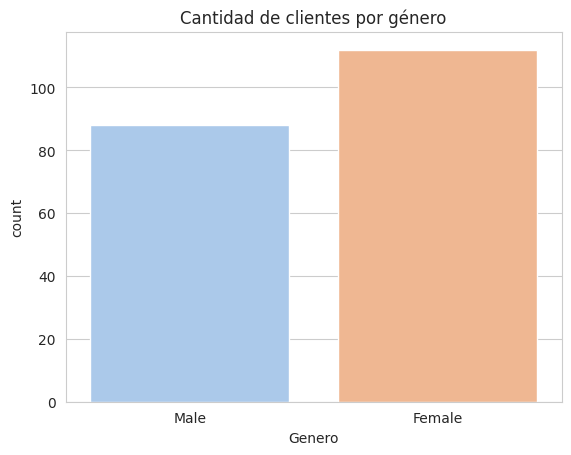

In [4]:
print(df[["Edad", "Ingreso", "Puntaje"]].describe().round(2))
print("\n", df["Genero"].value_counts())

sns.countplot(data=df, x="Genero", hue="Genero", palette="pastel", legend=False)
plt.title("Cantidad de clientes por género")
plt.show()

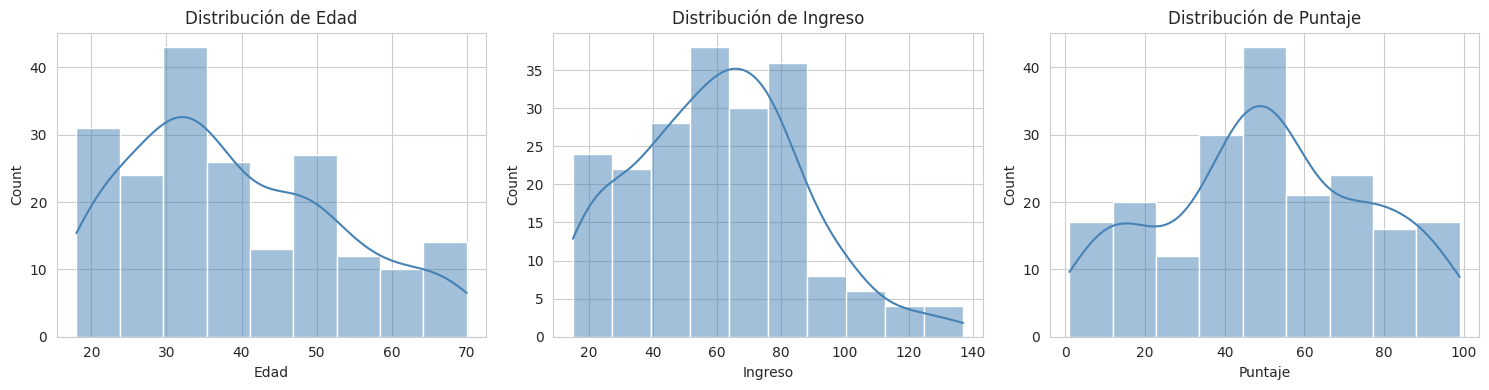

In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, col in zip(ejes, ["Edad", "Ingreso", "Puntaje"]):
    sns.histplot(df[col], kde=True, ax=eje, color="steelblue")
    eje.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

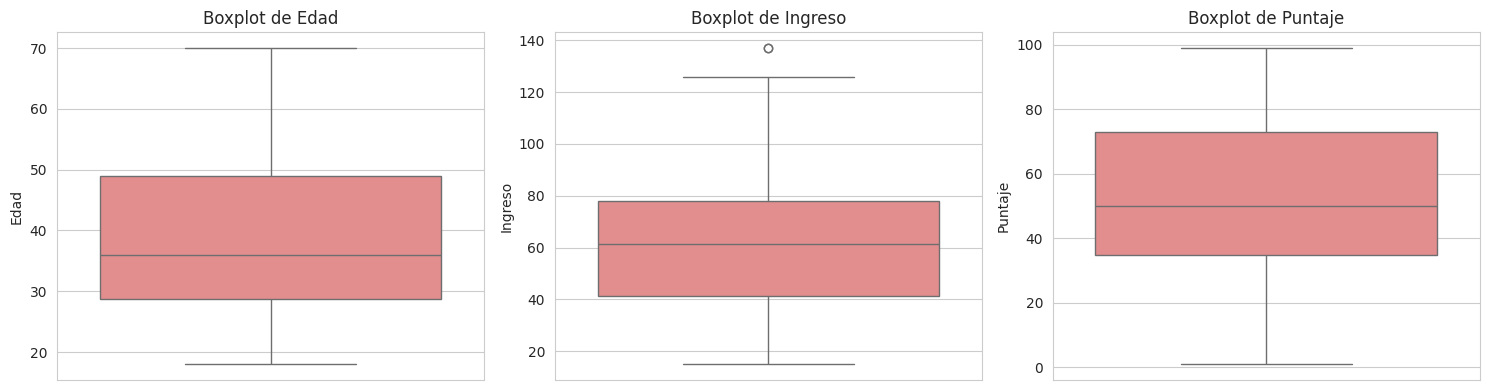

Edad: límites [-1.62, 79.38] -> 0 atípicos
Ingreso: límites [-13.25, 132.75] -> 2 atípicos
Puntaje: límites [-22.62, 130.38] -> 0 atípicos


In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, col in zip(ejes, ["Edad", "Ingreso", "Puntaje"]):
    sns.boxplot(y=df[col], ax=eje, color="lightcoral")
    eje.set_title(f"Boxplot de {col}")
plt.tight_layout()
plt.show()

for col in ["Edad", "Ingreso", "Puntaje"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    atipicos = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"{col}: límites [{lim_inf:.2f}, {lim_sup:.2f}] -> {len(atipicos)} atípicos")

### Limpieza de datos

In [7]:
df_limpio = df.copy()
df_limpio = df_limpio.drop(columns=["CustomerID"])

antes = len(df_limpio)
df_limpio = df_limpio.dropna()
df_limpio = df_limpio.drop_duplicates()
print("Filas eliminadas por nulos o duplicados:", antes - len(df_limpio))

df_limpio["Genero"] = df_limpio["Genero"].str.strip().str.capitalize()
print("Categorías de Genero:", df_limpio["Genero"].unique())

print("Edad fuera de rango (18-100):", ((df_limpio["Edad"] < 18) | (df_limpio["Edad"] > 100)).sum())
print("Ingreso negativo o cero:", (df_limpio["Ingreso"] <= 0).sum())
print("Puntaje fuera de 1-100:", ((df_limpio["Puntaje"] < 1) | (df_limpio["Puntaje"] > 100)).sum())

print("\nTamaño final:", df_limpio.shape)
df_limpio.head()

Filas eliminadas por nulos o duplicados: 0
Categorías de Genero: ['Male' 'Female']
Edad fuera de rango (18-100): 0
Ingreso negativo o cero: 0
Puntaje fuera de 1-100: 0

Tamaño final: (200, 4)


,Genero,Edad,Ingreso,Puntaje
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


**Decisiones de limpieza:**
- Se eliminó `CustomerID` por ser un identificador sin significado para la segmentación.
- No se encontraron valores nulos ni registros duplicados.
- Se estandarizó el texto de la variable `Genero`.
- Todos los valores están dentro de rangos válidos.
- Los 2 valores atípicos de `Ingreso` (137 k$) **se conservan**, porque son datos reales y plausibles de clientes de altos ingresos, no errores de captura.

A partir de aquí se trabaja con `df_limpio`.

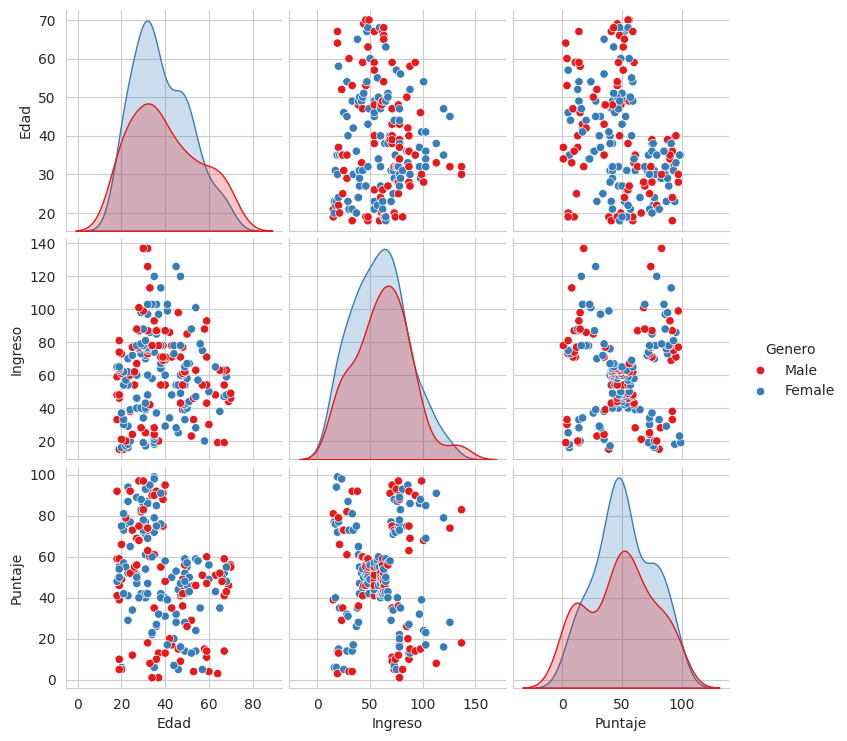

In [8]:
sns.pairplot(df_limpio, vars=["Edad", "Ingreso", "Puntaje"], hue="Genero", palette="Set1")
plt.show()

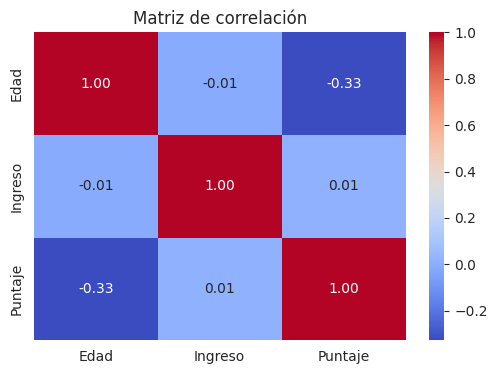

In [9]:
plt.figure(figsize=(6, 4))
sns.heatmap(df_limpio[["Edad", "Ingreso", "Puntaje"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación")
plt.show()

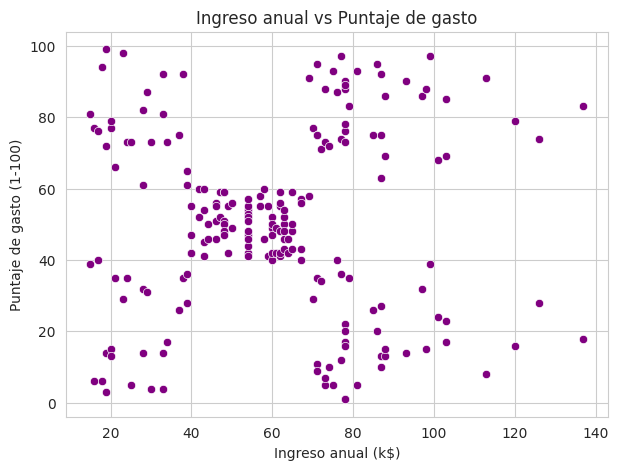

In [10]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_limpio, x="Ingreso", y="Puntaje", color="purple")
plt.title("Ingreso anual vs Puntaje de gasto")
plt.xlabel("Ingreso anual (k$)")
plt.ylabel("Puntaje de gasto (1-100)")
plt.show()

### Preguntas – Parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**
Las más adecuadas son **Ingreso anual** y **Puntaje de gasto**, porque describen la capacidad de compra y el comportamiento de consumo, que es lo que interesa en marketing. En su diagrama de dispersión se observan agrupaciones bien definidas. `CustomerID` no aporta información (es un identificador) y `Genero` es categórica y no muestra diferencias marcadas. La `Edad` podría complementar, pero usar dos variables permite visualizar los clusters en un plano y facilita la interpretación.

**¿Se identifican valores atípicos?**
Con la regla del rango intercuartílico (IQR), solo **Ingreso** presenta **2 valores atípicos** (137 k$), que superan el límite superior de 132.75. Edad y Puntaje no presentan atípicos. Como se justificó en la limpieza, se **conservan** porque son valores reales y plausibles, y son muy pocos para distorsionar el modelo.

**¿Qué tipo de relaciones se observan entre las variables?**
- **Ingreso vs Puntaje:** correlación prácticamente nula (≈ 0.01), no hay relación lineal; pero el diagrama de dispersión muestra unos **cinco grupos**, es decir, la relación es por segmentos, ideal para clustering.
- **Edad vs Puntaje:** correlación negativa moderada (≈ -0.33): los clientes más jóvenes tienden a gastar más.
- **Edad vs Ingreso:** sin relación apreciable (≈ -0.01).

## Parte 2 – Preprocesamiento

In [11]:
variables = ["Ingreso", "Puntaje"]
X = df_limpio[variables]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=variables)

print("ANTES de escalar:")
print(X.describe().loc[["mean", "std", "min", "max"]].round(2))
print("\nDESPUÉS de escalar:")
print(X_scaled_df.describe().loc[["mean", "std", "min", "max"]].round(2))

ANTES de escalar:
      Ingreso  Puntaje
mean    60.56    50.20
std     26.26    25.82
min     15.00     1.00
max    137.00    99.00

DESPUÉS de escalar:
      Ingreso  Puntaje
mean    -0.00    -0.00
std      1.00     1.00
min     -1.74    -1.91
max      2.92     1.89


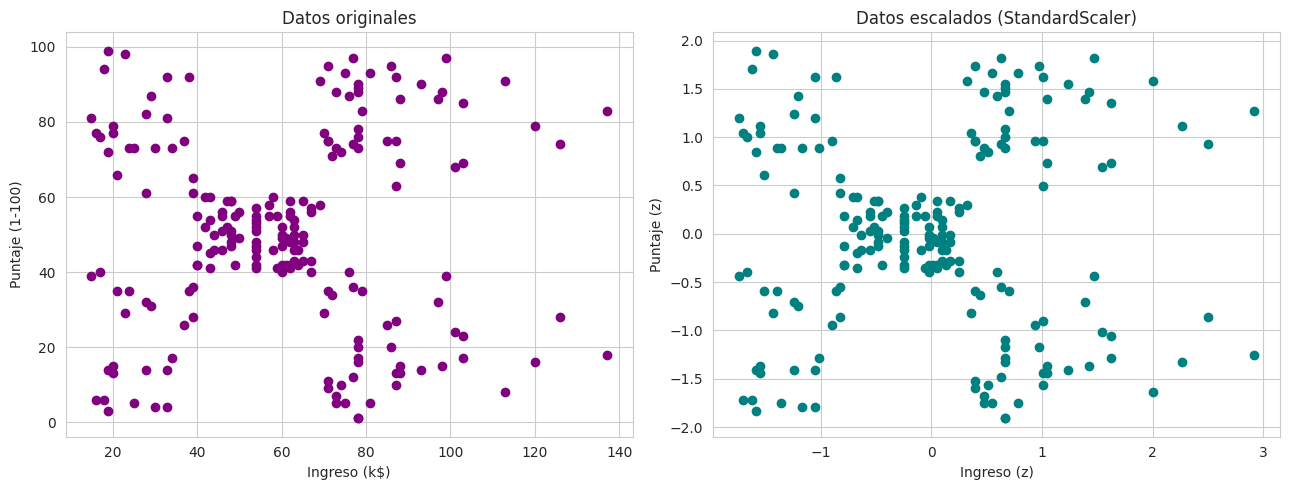

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

ejes[0].scatter(X["Ingreso"], X["Puntaje"], color="purple")
ejes[0].set_title("Datos originales")
ejes[0].set_xlabel("Ingreso (k$)")
ejes[0].set_ylabel("Puntaje (1-100)")

ejes[1].scatter(X_scaled_df["Ingreso"], X_scaled_df["Puntaje"], color="teal")
ejes[1].set_title("Datos escalados (StandardScaler)")
ejes[1].set_xlabel("Ingreso (z)")
ejes[1].set_ylabel("Puntaje (z)")

plt.tight_layout()
plt.show()

### Pregunta – Parte 2

**¿Por qué es necesario escalar las variables en el algoritmo K-Means?**
Porque K-Means asigna cada observación al centroide más cercano usando la **distancia euclidiana**. Si las variables tienen rangos distintos (Ingreso de 15 a 137 y Puntaje de 1 a 99), la variable con valores más grandes domina el cálculo de la distancia y el algoritmo termina agrupando casi solo según ella, ignorando a las demás.

Con **StandardScaler** cada variable se transforma con z = (x − media) / desviación estándar, quedando con media 0 y desviación 1. Así todas aportan **por igual** a la distancia. Como se ve en la gráfica, el escalado no altera la forma ni la estructura de los grupos, solo pone las variables en una escala comparable.

## Parte 3 – Método del Codo

In [13]:
inercias = []
rango_k = range(1, 11)

for k in rango_k:
    modelo = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    modelo.fit(X_scaled)
    inercias.append(modelo.inertia_)

tabla_codo = pd.DataFrame({"K": list(rango_k), "Inercia": inercias})
tabla_codo["Reducción (%)"] = (tabla_codo["Inercia"].pct_change() * -100).round(1)
tabla_codo["Inercia"] = tabla_codo["Inercia"].round(2)
tabla_codo

,K,Inercia,Reducción (%)
0,1,400.00,NaN
1,2,269.69,32.6
2,3,157.70,41.5
3,4,108.92,30.9
4,5,65.57,39.8
5,6,55.06,16.0
6,7,44.86,18.5
7,8,37.23,17.0
8,9,32.39,13.0
9,10,29.98,7.4


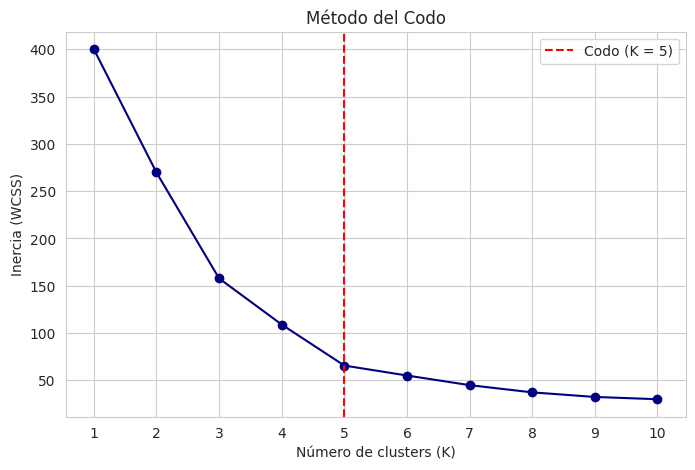

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(rango_k, inercias, marker="o", linestyle="-", color="navy")
plt.axvline(x=5, color="red", linestyle="--", label="Codo (K = 5)")
plt.title("Método del Codo")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia (WCSS)")
plt.xticks(rango_k)
plt.legend()
plt.show()

### Preguntas – Parte 3

**¿Por qué valores cercanos a cero indican mejor ajuste?**
La inercia (WCSS) es la suma de las distancias al cuadrado entre cada observación y el centroide de su cluster. Un valor cercano a cero significa que los puntos están muy cerca de su centroide, es decir, los grupos son **compactos y homogéneos**: los clientes de un mismo cluster se parecen mucho entre sí.

Sin embargo, la inercia **siempre disminuye** al aumentar K, y llega a cero si cada observación es su propio cluster (K = n), lo cual no tiene ninguna utilidad. Por eso no se busca la inercia mínima absoluta, sino el equilibrio entre grupos compactos y un número de clusters interpretable.

**¿Cómo se identifica el punto óptimo de K?**
Se grafica la inercia contra K y se busca el **"codo"**: el punto donde la curva deja de caer bruscamente y empieza a aplanarse. A partir de ahí, agregar más clusters solo produce mejoras pequeñas que no justifican la complejidad adicional.

En este caso, la inercia baja de forma pronunciada hasta **K = 5** (reducciones entre 30 % y 42 %), y desde K = 6 las reducciones caen a menos del 19 %. Por lo tanto, el método del codo sugiere **K = 5** como número óptimo de clusters, lo cual coincide con las cinco agrupaciones observadas en el diagrama de dispersión de la Parte 1.

## Parte 4 – Coeficiente de Silueta

In [15]:
siluetas = []
rango_k_sil = range(2, 11)

for k in rango_k_sil:
    modelo = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    etiquetas_k = modelo.fit_predict(X_scaled)
    siluetas.append(silhouette_score(X_scaled, etiquetas_k))

tabla_sil = pd.DataFrame({"K": list(rango_k_sil), "Silueta": siluetas}).round(4)
k_mejor = tabla_sil.loc[tabla_sil["Silueta"].idxmax(), "K"]
print("Mejor K según la silueta:", k_mejor)
tabla_sil

Mejor K según la silueta: 5


,K,Silueta
0,2,0.3213
1,3,0.4666
2,4,0.4939
3,5,0.5547
4,6,0.5399
5,7,0.5281
6,8,0.4552
7,9,0.4571
8,10,0.4432


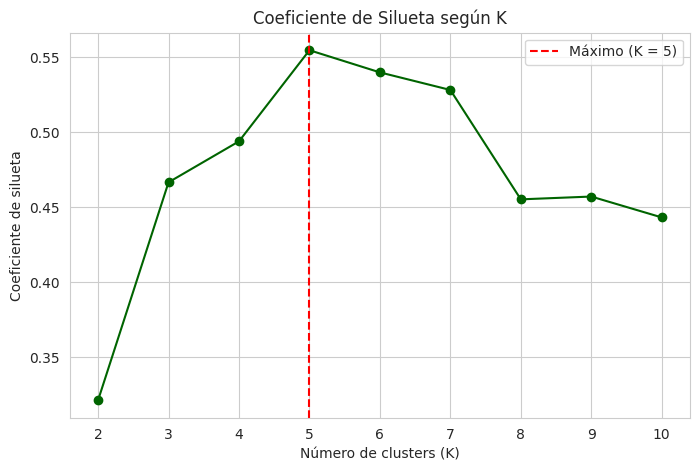

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(rango_k_sil, siluetas, marker="o", color="darkgreen")
plt.axvline(x=k_mejor, color="red", linestyle="--", label=f"Máximo (K = {k_mejor})")
plt.title("Coeficiente de Silueta según K")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(rango_k_sil)
plt.legend()
plt.show()

### Preguntas – Parte 4

**¿Qué mide el coeficiente de silueta?**
Mide qué tan bien está asignada cada observación a su cluster, combinando dos aspectos: la **cohesión** (qué tan cerca está de los puntos de su propio grupo, *a*) y la **separación** (qué tan lejos está de los puntos del grupo vecino más cercano, *b*). Se calcula como s = (b − a) / max(a, b) y su valor está entre −1 y 1. El coeficiente del modelo es el promedio de todas las observaciones.

**¿Qué significa un valor cercano a 1?**
Que las observaciones están muy cerca de los puntos de su propio cluster y muy lejos de los demás clusters. Es decir, los grupos son **compactos y bien separados**, lo que indica una segmentación de buena calidad.

**¿Qué implica un valor cercano a 0 o negativo?**
Un valor cercano a **0** indica que las observaciones están en la **frontera** entre dos clusters, por lo que los grupos se traslapan y no están claramente definidos. Un valor **negativo** indica que la observación está más cerca de otro cluster que del suyo, es decir, probablemente fue **mal asignada**, lo que sugiere que el número de clusters elegido no es adecuado.

**¿Coincide el valor óptimo de K con el método del codo? Justifique.**
**Sí, coinciden.** El método del codo mostró que la inercia deja de disminuir significativamente a partir de **K = 5**, y el coeficiente de silueta alcanza su valor máximo también en **K = 5** (≈ 0.555), disminuyendo para valores mayores. Ambos métodos se complementan: el codo indica que con 5 clusters los grupos ya son compactos, y la silueta confirma que además están bien separados entre sí. Esto concuerda con las cinco agrupaciones visibles en el diagrama de dispersión de Ingreso vs Puntaje. Por lo tanto, se selecciona **K = 5**.

## Parte 5 – Modelo K-Means

In [17]:
k_optimo = 5
kmeans = KMeans(n_clusters=k_optimo, init="k-means++", n_init=10, random_state=42)
etiquetas = kmeans.fit_predict(X_scaled)

df_limpio["Cluster"] = etiquetas

print("Clientes por cluster:")
print(df_limpio["Cluster"].value_counts().sort_index())
print("\nInercia del modelo:", round(kmeans.inertia_, 2))
print("Silueta del modelo:", round(silhouette_score(X_scaled, etiquetas), 4))
df_limpio.head(10)

Clientes por cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Inercia del modelo: 65.57
Silueta del modelo: 0.5547


,Genero,Edad,Ingreso,Puntaje,Cluster
0,Male,19,15,39,4
1,Male,21,15,81,2
2,Female,20,16,6,4
3,Female,23,16,77,2
4,Female,31,17,40,4
5,Female,22,17,76,2
6,Female,35,18,6,4
7,Female,23,18,94,2
8,Male,64,19,3,4
9,Female,30,19,72,2


In [18]:
centroides_esc = kmeans.cluster_centers_
centroides = scaler.inverse_transform(centroides_esc)

centroides_df = pd.DataFrame(centroides, columns=variables).round(2)
centroides_df.index.name = "Cluster"
centroides_df

,Ingreso,Puntaje
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


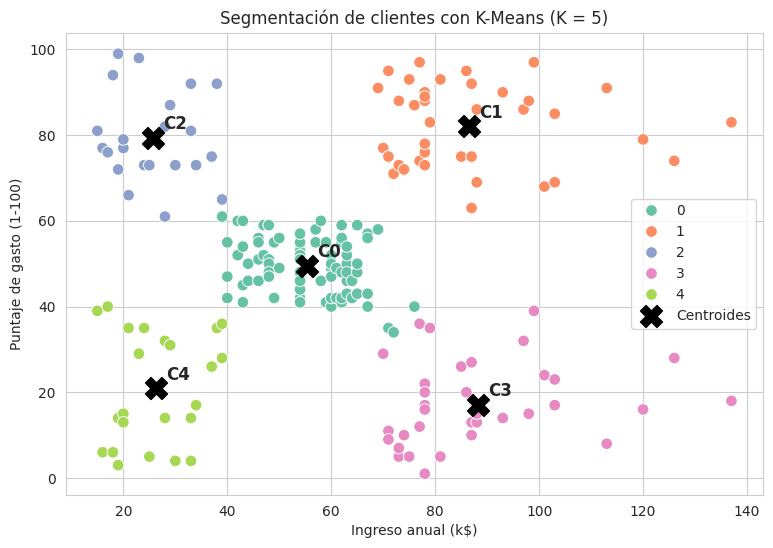

In [19]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_limpio, x="Ingreso", y="Puntaje", hue="Cluster", palette="Set2", s=70)
plt.scatter(centroides_df["Ingreso"], centroides_df["Puntaje"], c="black", marker="X", s=250, label="Centroides")
for i, fila in centroides_df.iterrows():
    plt.text(fila["Ingreso"] + 2, fila["Puntaje"] + 2, f"C{i}", fontsize=12, fontweight="bold")
plt.title("Segmentación de clientes con K-Means (K = 5)")
plt.xlabel("Ingreso anual (k$)")
plt.ylabel("Puntaje de gasto (1-100)")
plt.legend()
plt.show()

In [20]:
resumen = df_limpio.groupby("Cluster").agg(
    Clientes=("Ingreso", "count"),
    Edad_prom=("Edad", "mean"),
    Ingreso_prom=("Ingreso", "mean"),
    Puntaje_prom=("Puntaje", "mean")
).round(1)

resumen["% del total"] = (resumen["Clientes"] / len(df_limpio) * 100).round(1)
resumen["% Mujeres"] = (df_limpio.groupby("Cluster")["Genero"].apply(lambda g: (g == "Female").mean() * 100)).round(1)
resumen

,Clientes,Edad_prom,Ingreso_prom,Puntaje_prom,% del total,% Mujeres
Cluster,,,,,,
0,81,42.7,55.3,49.5,40.5,59.3
1,39,32.7,86.5,82.1,19.5,53.8
2,22,25.3,25.7,79.4,11.0,59.1
3,35,41.1,88.2,17.1,17.5,45.7
4,23,45.2,26.3,20.9,11.5,60.9


### Preguntas – Parte 5

**¿Qué representa cada cluster?**
Cada cluster representa un grupo de clientes con un comportamiento similar en cuanto a **ingreso anual** y **puntaje de gasto**. Su centroide es el "cliente típico" del grupo:

- **Cluster 0 – Ingreso medio, gasto medio (81 clientes, 40.5 %):** ingreso promedio de 55.3 k$ y puntaje de 49.5. Es el grupo más grande; clientes de edad media (42.7 años) con un consumo moderado y estable. El 59.3 % son mujeres.
- **Cluster 1 – Ingreso alto, gasto alto (39 clientes, 19.5 %):** ingreso promedio de 86.5 k$ y puntaje de 82.1. Clientes relativamente jóvenes (32.7 años) con alto poder adquisitivo que además gastan mucho en el centro comercial. El 53.8 % son mujeres.
- **Cluster 2 – Ingreso bajo, gasto alto (22 clientes, 11.0 %):** ingreso promedio de 25.7 k$ pero puntaje de 79.4. Son los más jóvenes (25.3 años) y gastan mucho a pesar de tener ingresos bajos. El 59.1 % son mujeres.
- **Cluster 3 – Ingreso alto, gasto bajo (35 clientes, 17.5 %):** ingreso promedio de 88.2 k$ pero puntaje de apenas 17.1. Tienen capacidad económica, pero gastan poco en el centro comercial (41.1 años). Es el único grupo con mayoría de hombres (45.7 % mujeres).
- **Cluster 4 – Ingreso bajo, gasto bajo (23 clientes, 11.5 %):** ingreso promedio de 26.3 k$ y puntaje de 20.9. Son los de mayor edad (45.2 años), con poco ingreso y poco consumo. El 60.9 % son mujeres.

**¿Qué diferencias existen entre los grupos obtenidos?**
- **Por ingreso:** se distinguen tres niveles: bajo (clusters 2 y 4, ≈ 26 k$), medio (cluster 0, ≈ 55 k$) y alto (clusters 1 y 3, ≈ 87 k$).
- **Por gasto:** dentro de un mismo nivel de ingreso hay grupos opuestos. Con ingreso alto, el cluster 1 gasta mucho (82.1) y el cluster 3 muy poco (17.1); con ingreso bajo, el cluster 2 gasta mucho (79.4) y el cluster 4 poco (20.9). Esto confirma que **ingreso y gasto no van necesariamente juntos**, como mostró la correlación cercana a 0 de la Parte 1.
- **Por edad:** los grupos de **gasto alto** son los más jóvenes (cluster 2 con 25.3 años y cluster 1 con 32.7), mientras que los de **gasto bajo** tienen mayor edad (cluster 3 con 41.1 y cluster 4 con 45.2), lo que coincide con la correlación negativa entre Edad y Puntaje.
- **Por género:** en casi todos los grupos predominan las mujeres (54 % – 61 %), excepto en el cluster 3, donde predominan los hombres.
- **Por tamaño:** el cluster 0 concentra el 40.5 % de los clientes, mientras que los grupos de ingreso bajo (2 y 4) son los más pequeños, con alrededor del 11 % cada uno.